In [ ]:

# 🏠 RealtyScope
## Advanced Real Estate Analytics & Housing Price Prediction

### Data Science & Machine Learning Internship Project

**Project Objective:**

Develop an end-to-end Machine Learning system to analyze California housing data, identify important factors influencing housing prices, and predict median house values using regression techniques.

### Key Technologies
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Plotly
- ipywidgets

### Machine Learning Models
1. Ordinary Least Squares (OLS) Regression
2. Ridge Regression (L2)
3. Lasso Regression (L1)

### Advanced Features
1. Interactive Real Estate Analytics Dashboard
2. ML Model Battle Arena
3. California Housing Intelligence Map
4. Explainable AI (XAI)
5. Live House Price Prediction Simulator

**Dataset:** California Housing Dataset (`housing.csv`)

**Prediction Target:** `median_house_value`


In [3]:

%pip install -q pandas numpy matplotlib seaborn scikit-learn plotly ipywidgets statsmodels

# RealtyScope - Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as widgets
import warnings

from IPython.display import display, clear_output

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42

print("RealtyScope initialized successfully!")
print("All required libraries imported.")


Note: you may need to restart the kernel to use updated packages.
RealtyScope initialized successfully!
All required libraries imported.


In [4]:

# Load California Housing Dataset

from pathlib import Path

csv_path = Path("housing.csv")

if not csv_path.exists():
    raise FileNotFoundError(
        "housing.csv not found. Place it in the same "
        "working directory as your notebook."
    )

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Total Rows: 20640
Total Columns: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [5]:

# Dataset Overview

print("=" * 55)
print("REAL T Y SCOPE - DATASET OVERVIEW".replace(" ", ""))
print("=" * 55)

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Count"))

print("\nDuplicate Rows:", df.duplicated().sum())


REALTYSCOPE-DATASETOVERVIEW

Dataset Shape:
(20640, 10)

Column Names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage:

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
longitude,20640.0,NaN,NaN,NaN,-119.569704,2.003532,-124.35,-121.8,-118.49,-118.01,-114.31
latitude,20640.0,NaN,NaN,NaN,35.631861,2.135952,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,NaN,NaN,NaN,28.639486,12.585558,1.0,18.0,29.0,37.0,52.0
total_rooms,20640.0,NaN,NaN,NaN,2635.763081,2181.615252,2.0,1447.75,2127.0,3148.0,39320.0
total_bedrooms,20433.0,NaN,NaN,NaN,537.870553,421.38507,1.0,296.0,435.0,647.0,6445.0
population,20640.0,NaN,NaN,NaN,1425.476744,1132.462122,3.0,787.0,1166.0,1725.0,35682.0
households,20640.0,NaN,NaN,NaN,499.53968,382.329753,1.0,280.0,409.0,605.0,6082.0
median_income,20640.0,NaN,NaN,NaN,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,NaN,NaN,NaN,206855.816909,115395.615874,14999.0,119600.0,179700.0,264725.0,500001.0
ocean_proximity,20640,5,<1H OCEAN,9136,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:


,Missing Count
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0



Duplicate Rows: 0


In [7]:

# Step 6 - Intelligent Data Quality Analyzer

print("=" * 65)
print("REALTY SCOPE | INTELLIGENT DATA QUALITY ANALYZER")
print("=" * 65)

quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isnull().sum().values,
    "Missing (%)": (df.isnull().mean() * 100).round(2).values,
    "Unique Values": df.nunique().values
})

display(quality_report)

# Duplicate analysis
duplicate_count = df.duplicated().sum()

# Missing value analysis
total_cells = df.size
missing_cells = df.isnull().sum().sum()

completeness_score = (
    (1 - missing_cells / total_cells) * 100
)

print(f"\nDuplicate Records: {duplicate_count}")
print(f"Missing Cells: {missing_cells}")
print(f"Data Completeness Score: {completeness_score:.2f}%")

# IQR-based outlier analysis
numeric_columns = df.select_dtypes(
    include=np.number
).columns

outlier_results = []

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) |
                (df[col] > upper)).sum()

    outlier_results.append({
        "Feature": col,
        "Outlier Count": outliers,
        "Outlier (%)": round(
            outliers / len(df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)

print("\nOutlier Detection Report:")
display(outlier_df)

# Automated recommendations
print("\nAUTOMATED RECOMMENDATIONS")

if missing_cells > 0:
    print("Missing values detected: use imputation.")
else:
    print("No missing values detected.")

if duplicate_count > 0:
    print("Duplicate records detected: investigate duplicates.")
else:
    print("No duplicate records detected.")

if (outlier_df["Outlier Count"] > 0).any():
    print("Potential outliers detected: investigate before removal.")
else:
    print("No IQR-based outliers detected.")

print("\nData quality analysis completed!")


REALTY SCOPE | INTELLIGENT DATA QUALITY ANALYZER


,Column,Data Type,Missing Values,Missing (%),Unique Values
0,longitude,float64,0,0.0,844
1,latitude,float64,0,0.0,862
2,housing_median_age,float64,0,0.0,52
3,total_rooms,float64,0,0.0,5926
4,total_bedrooms,float64,207,1.0,1923
5,population,float64,0,0.0,3888
6,households,float64,0,0.0,1815
7,median_income,float64,0,0.0,12928
8,median_house_value,float64,0,0.0,3842
9,ocean_proximity,object,0,0.0,5



Duplicate Records: 0
Missing Cells: 207
Data Completeness Score: 99.90%

Outlier Detection Report:


,Feature,Outlier Count,Outlier (%)
0,longitude,0,0.00
1,latitude,0,0.00
2,housing_median_age,0,0.00
3,total_rooms,1287,6.24
4,total_bedrooms,1271,6.16
5,population,1196,5.79
6,households,1220,5.91
7,median_income,681,3.30
8,median_house_value,1071,5.19



AUTOMATED RECOMMENDATIONS
Missing values detected: use imputation.
No duplicate records detected.
Potential outliers detected: investigate before removal.

Data quality analysis completed!


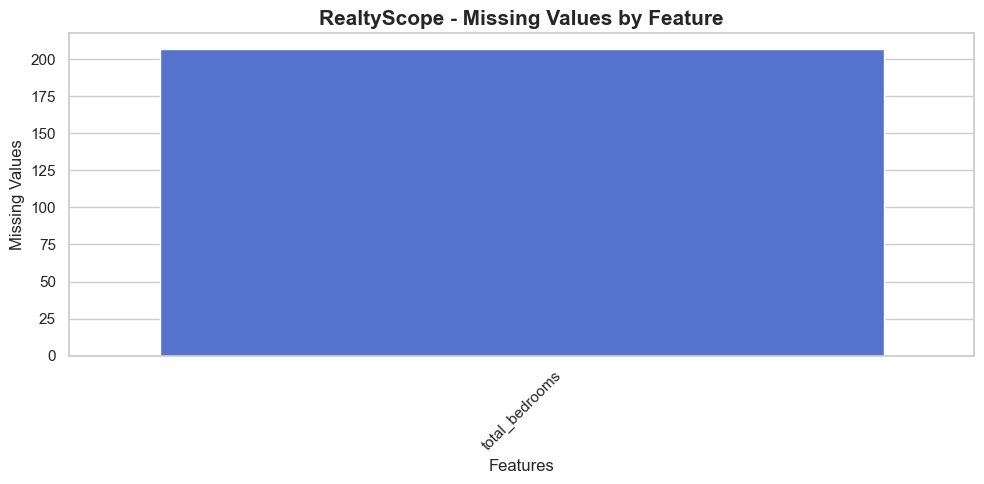

In [8]:

# Missing Values Visualization

missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

plt.figure(figsize=(10, 5))

if not missing_counts.empty:
    sns.barplot(
        x=missing_counts.index,
        y=missing_counts.values,
        color="royalblue"
    )

    plt.title(
        "RealtyScope - Missing Values by Feature",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Features")
    plt.ylabel("Missing Values")
    plt.xticks(rotation=45)
else:
    plt.text(
        0.5, 0.5,
        "No Missing Values Detected",
        ha="center",
        va="center",
        fontsize=16
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


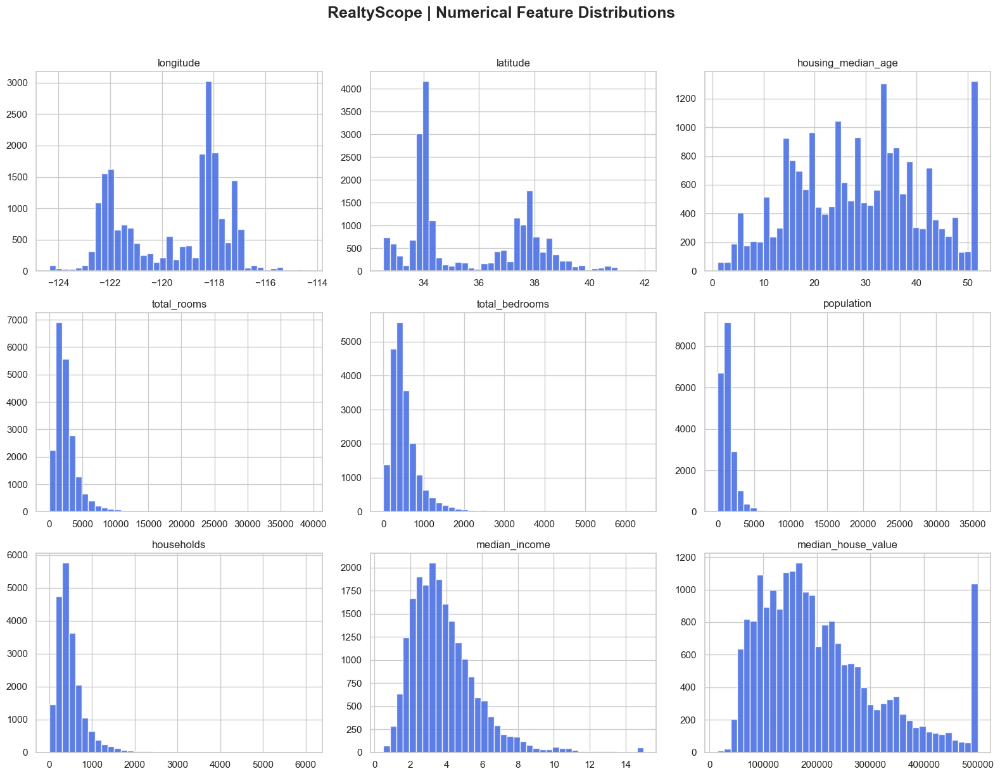

In [9]:

numeric_df = df.select_dtypes(include=np.number)

numeric_df.hist(
    bins=40,
    figsize=(16, 12),
    color="royalblue",
    edgecolor="white",
    alpha=0.85
)

plt.suptitle(
    "RealtyScope | Numerical Feature Distributions",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()


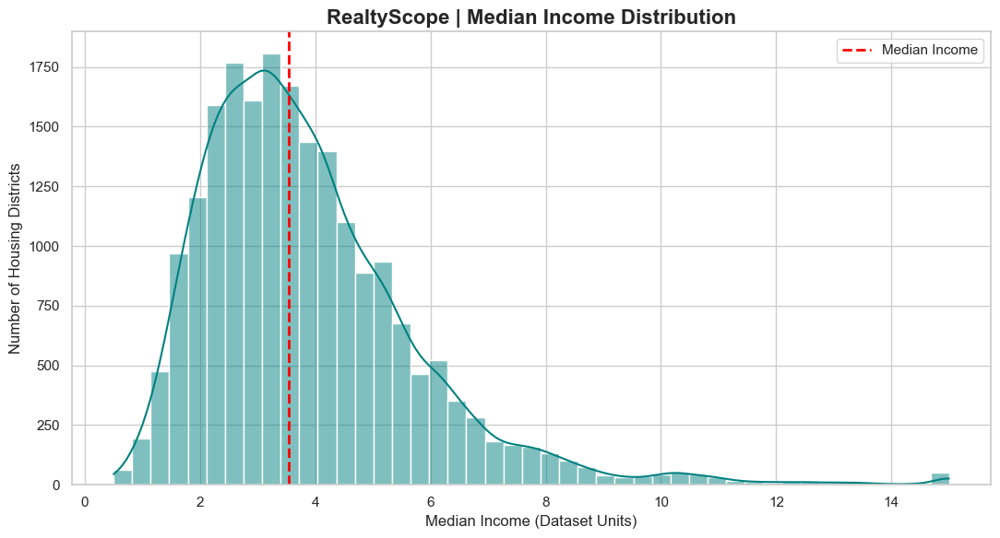

In [11]:

plt.figure(figsize=(11, 6))

sns.histplot(
    data=df,
    x="median_income",
    bins=45,
    kde=True,
    color="teal"
)

plt.axvline(
    df["median_income"].median(),
    color="red",
    linestyle="--",
    linewidth=2,
    label="Median Income"
)

plt.title(
    "RealtyScope | Median Income Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Median Income (Dataset Units)")
plt.ylabel("Number of Housing Districts")
plt.legend()
plt.tight_layout()
plt.show()


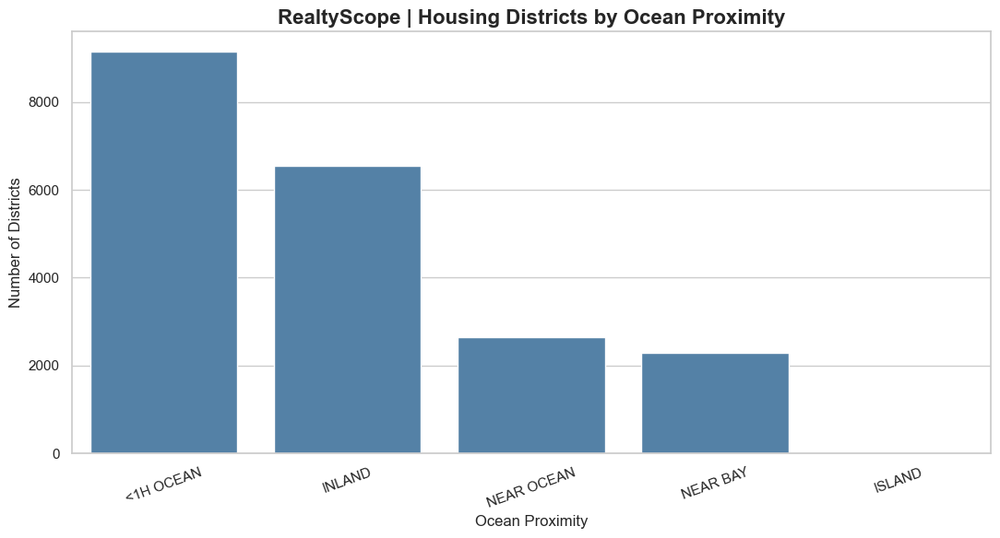

Ocean Proximity Distribution:


,Count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


In [12]:

plt.figure(figsize=(11, 6))

order = df["ocean_proximity"].value_counts().index

sns.countplot(
    data=df,
    x="ocean_proximity",
    order=order,
    color="steelblue"
)

plt.title(
    "RealtyScope | Housing Districts by Ocean Proximity",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Ocean Proximity")
plt.ylabel("Number of Districts")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("Ocean Proximity Distribution:")
display(df["ocean_proximity"].value_counts().to_frame("Count"))


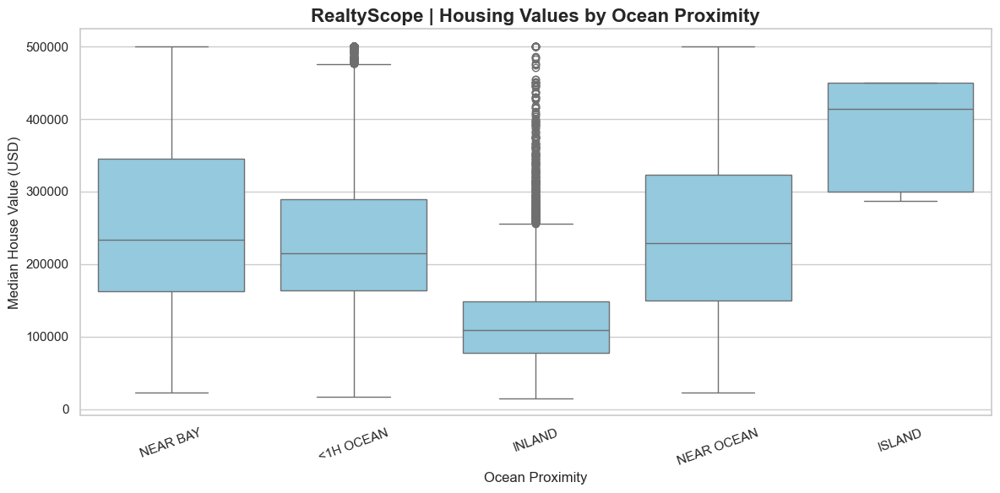

Median Housing Values by Ocean Proximity:


,count,mean,median
ocean_proximity,,,
ISLAND,5,380440.00,414700.0
NEAR BAY,2290,259212.31,233800.0
NEAR OCEAN,2658,249433.98,229450.0
<1H OCEAN,9136,240084.29,214850.0
INLAND,6551,124805.39,108500.0


In [13]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="ocean_proximity",
    y="median_house_value",
    color="skyblue"
)

plt.title(
    "RealtyScope | Housing Values by Ocean Proximity",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Ocean Proximity")
plt.ylabel("Median House Value (USD)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("Median Housing Values by Ocean Proximity:")

display(
    df.groupby("ocean_proximity")["median_house_value"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("median", ascending=False)
)


In [14]:

print("=" * 60)
print("REALTY SCOPE | AUTOMATED EDA INSIGHTS".replace(" ", ""))
print("=" * 60)

print(f"\nTotal Housing Districts: {len(df):,}")

print(
    f"Average Median House Value: "
    f"${df['median_house_value'].mean():,.2f}"
)

print(
    f"Median House Value: "
    f"${df['median_house_value'].median():,.2f}"
)

print(
    f"Average Housing Age: "
    f"{df['housing_median_age'].mean():.2f} years"
)

most_common_location = df["ocean_proximity"].mode()[0]

print(
    f"Most Common Ocean Proximity: "
    f"{most_common_location}"
)

income_correlation = df[
    ["median_income", "median_house_value"]
].corr().iloc[0, 1]

print(
    f"Income vs House Value Correlation: "
    f"{income_correlation:.3f}"
)

print("\nExploratory Data Analysis Completed!")


REALTYSCOPE|AUTOMATEDEDAINSIGHTS

Total Housing Districts: 20,640
Average Median House Value: $206,855.82
Median House Value: $179,700.00
Average Housing Age: 28.64 years
Most Common Ocean Proximity: <1H OCEAN
Income vs House Value Correlation: 0.688

Exploratory Data Analysis Completed!


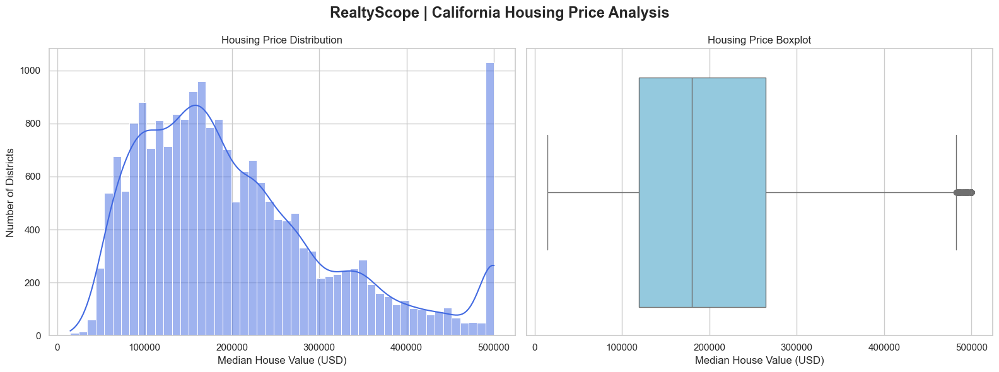

In [15]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(
    data=df,
    x="median_house_value",
    bins=50,
    kde=True,
    color="royalblue",
    ax=axes[0]
)

axes[0].set_title("Housing Price Distribution")
axes[0].set_xlabel("Median House Value (USD)")
axes[0].set_ylabel("Number of Districts")

sns.boxplot(
    x=df["median_house_value"],
    color="skyblue",
    ax=axes[1]
)

axes[1].set_title("Housing Price Boxplot")
axes[1].set_xlabel("Median House Value (USD)")

plt.suptitle(
    "RealtyScope | California Housing Price Analysis",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


REALTYSCOPE | HOUSING PRICE CAP ANALYSIS
Maximum Recorded Value: $500,001.00
Districts at Maximum Value: 965
Percentage at Maximum: 4.68%


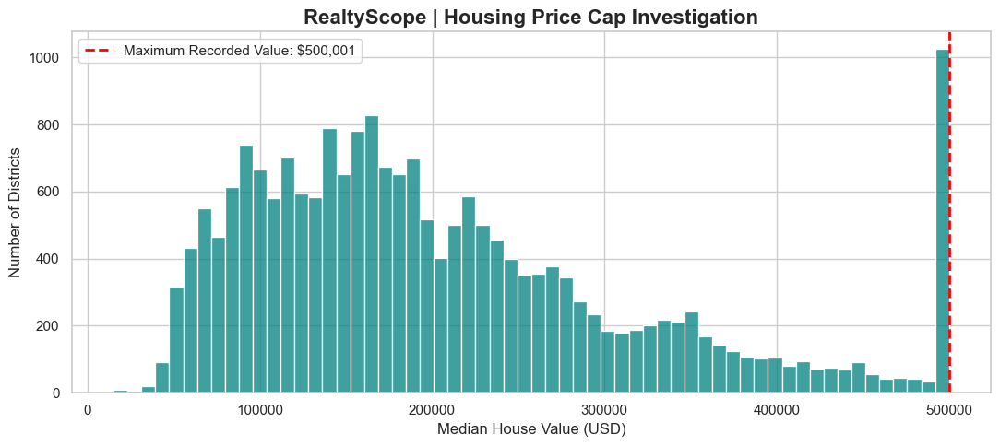


are concentrated at the maximum recorded price.
This suggests target-value censoring.


In [18]:

target = df["median_house_value"]

max_price = target.max()
cap_count = (target == max_price).sum()
cap_percentage = (cap_count / len(target)) * 100

print("=" * 60)
print("REALTYSCOPE | HOUSING PRICE CAP ANALYSIS")
print("=" * 60)

print(f"Maximum Recorded Value: ${max_price:,.2f}")
print(f"Districts at Maximum Value: {cap_count:,}")
print(f"Percentage at Maximum: {cap_percentage:.2f}%")

plt.figure(figsize=(11, 5))

sns.histplot(
    target,
    bins=60,
    color="teal"
)

plt.axvline(
    max_price,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Maximum Recorded Value: ${max_price:,.0f}"
)

plt.title(
    "RealtyScope | Housing Price Cap Investigation",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Median House Value (USD)")
plt.ylabel("Number of Districts")
plt.legend()
plt.tight_layout()
plt.show()

if cap_percentage > 1:
    print("\nWARNING: A substantial number of values")
    print("are concentrated at the maximum recorded price.")
    print("This suggests target-value censoring.")
else:
    print("\nNo substantial maximum-value concentration detected.")


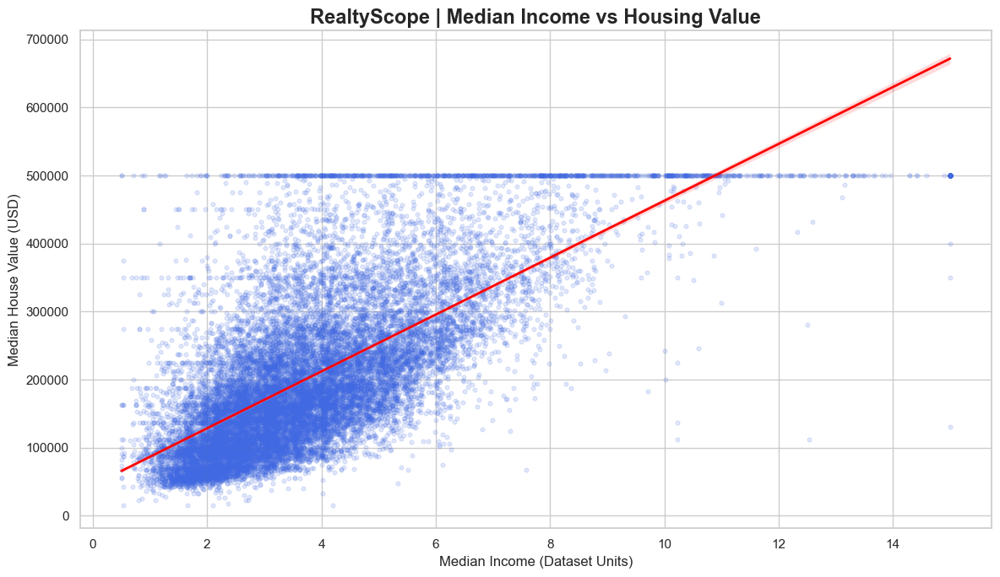

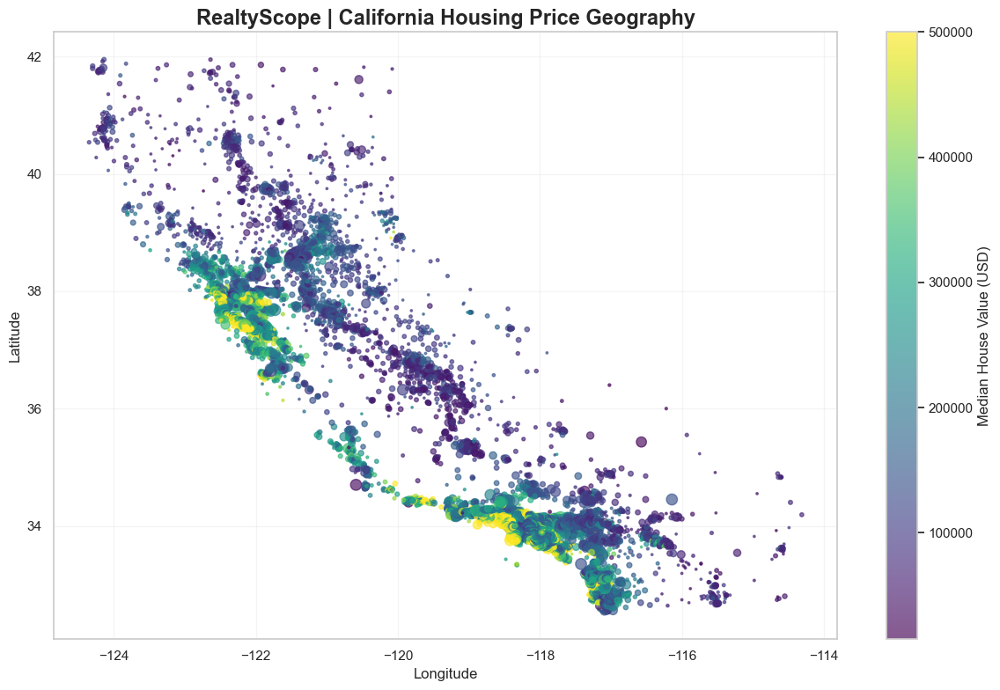

In [19]:

# Step 8.3 - Median Income vs Housing Price

plt.figure(figsize=(12, 7))

sns.regplot(
    data=df,
    x="median_income",
    y="median_house_value",
    scatter_kws={
        "alpha": 0.15,
        "s": 12,
        "color": "royalblue"
    },
    line_kws={
        "color": "red",
        "linewidth": 2
    }
)

plt.title(
    "RealtyScope | Median Income vs Housing Value",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Median Income (Dataset Units)")
plt.ylabel("Median House Value (USD)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["median_house_value"],
    s=np.clip(df["population"] / 100, 3, 80),
    cmap="viridis",
    alpha=0.65
)

plt.colorbar(
    scatter,
    label="Median House Value (USD)"
)

plt.title(
    "RealtyScope | California Housing Price Geography",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


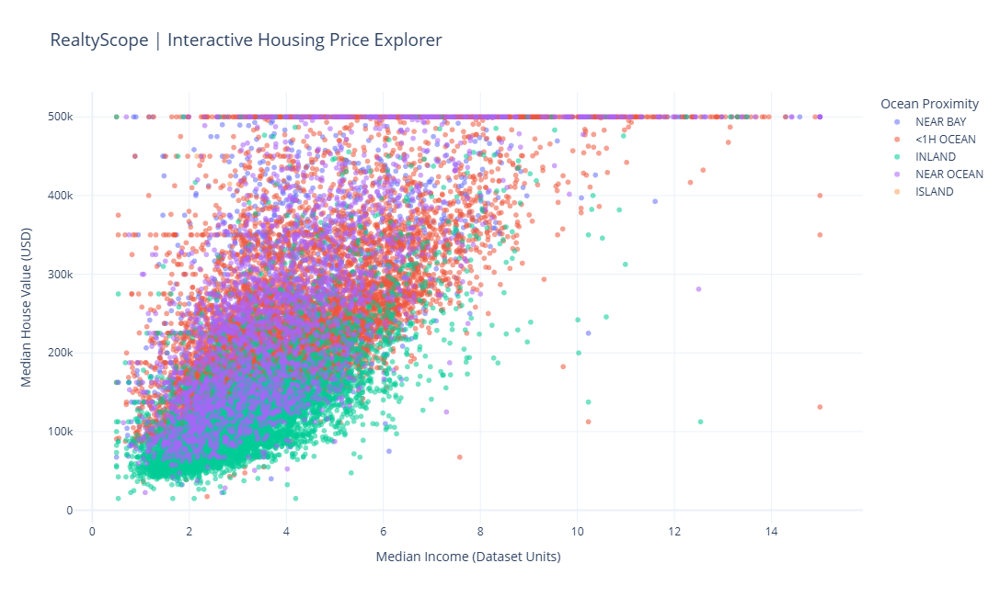

REALTYSCOPE | AUTOMATED HOUSING MARKET INSIGHTS

Average Median House Value: $206,855.82
Median House Value: $179,700.00
Minimum Recorded Value: $14,999.00
Maximum Recorded Value: $500,001.00

Standard Deviation: $115,395.62
Price Skewness: 0.978

Income-Price Correlation: 0.688

Housing Values by Ocean Proximity:


,count,mean,median
ocean_proximity,,,
ISLAND,5,380440.00,414700.0
NEAR BAY,2290,259212.31,233800.0
NEAR OCEAN,2658,249433.98,229450.0
<1H OCEAN,9136,240084.29,214850.0
INLAND,6551,124805.39,108500.0



INSIGHTS
- Median income has a strong positive linear association
  with median house value.
- Housing price cap may affect regression accuracy.
- Geographic and income relationships warrant further analysis.
- These observations are associations, not causal conclusions.

Step 8 analysis completed successfully!


In [20]:

fig = px.scatter(
    df,
    x="median_income",
    y="median_house_value",
    color="ocean_proximity",
    hover_data=[
        "housing_median_age",
        "population",
        "latitude",
        "longitude"
    ],
    opacity=0.55,
    title="RealtyScope | Interactive Housing Price Explorer",
    labels={
        "median_income": "Median Income (Dataset Units)",
        "median_house_value": "Median House Value (USD)",
        "ocean_proximity": "Ocean Proximity"
    }
)

fig.update_layout(
    template="plotly_white",
    height=650,
    title_font_size=19
)

fig.show()

price = df["median_house_value"]

print("=" * 65)
print("REALTYSCOPE | AUTOMATED HOUSING MARKET INSIGHTS")
print("=" * 65)

print(f"\nAverage Median House Value: ${price.mean():,.2f}")
print(f"Median House Value: ${price.median():,.2f}")
print(f"Minimum Recorded Value: ${price.min():,.2f}")
print(f"Maximum Recorded Value: ${price.max():,.2f}")

print(f"\nStandard Deviation: ${price.std():,.2f}")
print(f"Price Skewness: {price.skew():.3f}")

income_corr = df[
    ["median_income", "median_house_value"]
].corr().iloc[0, 1]

print(f"\nIncome-Price Correlation: {income_corr:.3f}")

location_summary = (
    df.groupby("ocean_proximity")["median_house_value"]
    .agg(["count", "mean", "median"])
    .sort_values("median", ascending=False)
)

print("\nHousing Values by Ocean Proximity:")
display(location_summary.round(2))

print("\nINSIGHTS")

if income_corr > 0.5:
    print("- Median income has a strong positive linear association")
    print("  with median house value.")
elif income_corr > 0:
    print("- Median income has a positive linear association")
    print("  with median house value.")
else:
    print("- No positive linear association was detected.")

if cap_percentage > 1:
    print("- Housing price cap may affect regression accuracy.")

print("- Geographic and income relationships warrant further analysis.")
print("- These observations are associations, not causal conclusions.")

print("\nStep 8 analysis completed successfully!")


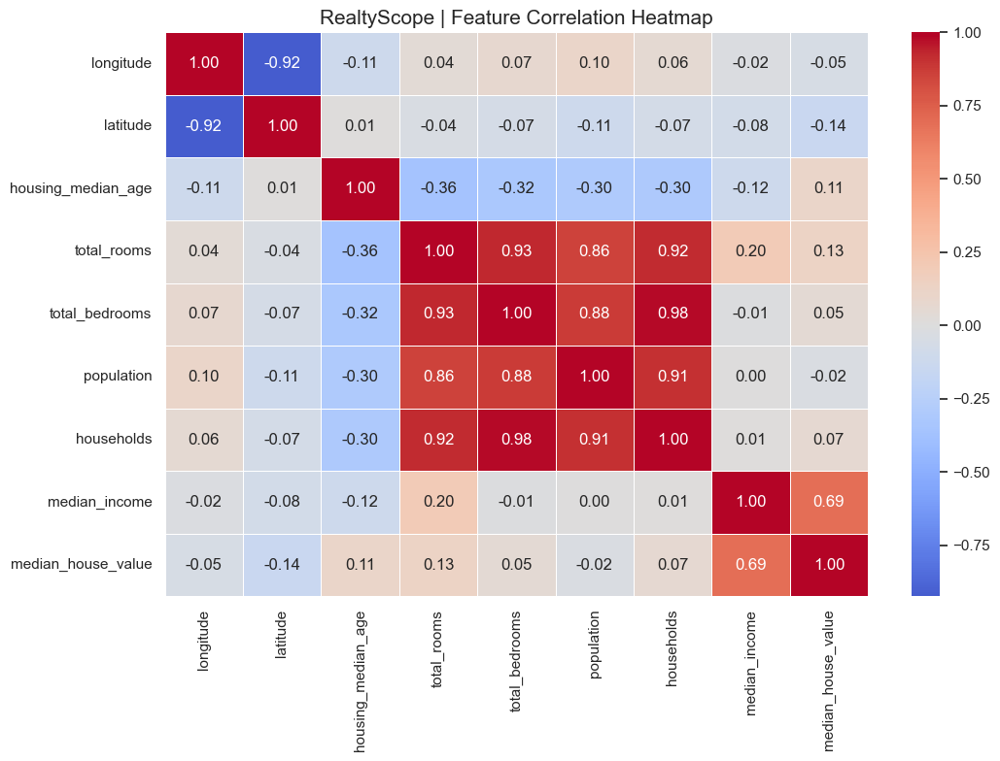

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

,Feature,VIF
6,households,28.28
4,total_bedrooms,26.88
3,total_rooms,12.13
1,latitude,8.83
0,longitude,8.70
5,population,6.26
7,median_income,1.69
2,housing_median_age,1.26


In [21]:

corr = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f",
            linewidths=0.5, center=0)
plt.title("RealtyScope | Feature Correlation Heatmap", fontsize=15)
plt.tight_layout()
plt.show()

display(corr["median_house_value"].sort_values(ascending=False))

from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X_vif = df.select_dtypes(include=np.number).drop(
    columns="median_house_value"
)
X_vif = SimpleImputer(strategy="median").fit_transform(X_vif)
X_vif = StandardScaler().fit_transform(X_vif)

vif = pd.DataFrame({
    "Feature": df.select_dtypes(include=np.number)
                 .drop(columns="median_house_value").columns,
    "VIF": [variance_inflation_factor(X_vif, i)
            for i in range(X_vif.shape[1])]
})

display(vif.sort_values("VIF", ascending=False).round(2))



In [22]:

def add_housing_features(data):
    data = data.copy()
    data["rooms_per_household"] = data["total_rooms"] / data["households"].replace(0, np.nan)
    data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"].replace(0, np.nan)
    data["population_per_household"] = data["population"] / data["households"].replace(0, np.nan)
    data["income_age_interaction"] = data["median_income"] * data["housing_median_age"]
    return data.replace([np.inf, -np.inf], np.nan)

df_fe = add_housing_features(df)

print("Feature Engineering Completed!")
print("Original Features:", df.shape[1])
print("Total Features:", df_fe.shape[1])

display(df_fe[[
    "rooms_per_household", "bedrooms_per_room",
    "population_per_household", "income_age_interaction"
]].head())


Feature Engineering Completed!
Original Features: 10
Total Features: 14


,rooms_per_household,bedrooms_per_room,population_per_household,income_age_interaction
0,6.984127,0.146591,2.555556,341.3332
1,6.238137,0.155797,2.109842,174.3294
2,8.288136,0.129516,2.802260,377.3848
3,5.817352,0.184458,2.547945,293.4412
4,6.281853,0.172096,2.181467,200.0024


In [23]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

X = df_fe.drop(columns="median_house_value")
y = df_fe["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Numerical Features:", len(num_cols))
print("Categorical Features:", len(cat_cols))
print("Preprocessing Pipeline Ready!")


Training Data: (16512, 13)
Testing Data: (4128, 13)
Numerical Features: 12
Categorical Features: 1
Preprocessing Pipeline Ready!


In [26]:

# Step 12 - Feature Scaling (Fixed)

from sklearn.preprocessing import StandardScaler

scaled_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

X_train_scaled = scaled_preprocessor.fit_transform(X_train)
X_test_scaled = scaled_preprocessor.transform(X_test)

print("Feature Scaling Completed Successfully!")
print("Training Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)


Feature Scaling Completed Successfully!
Training Shape: (16512, 17)
Testing Shape: (4128, 17)


In [27]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone

ols_model = Pipeline([
    ("preprocessing", clone(scaled_preprocessor)),
    ("model", LinearRegression())
])

ols_model.fit(X_train, y_train)
ols_pred = ols_model.predict(X_test)

ols_rmse = np.sqrt(mean_squared_error(y_test, ols_pred))
ols_mae = mean_absolute_error(y_test, ols_pred)
ols_r2 = r2_score(y_test, ols_pred)

print("RealtyScope | OLS Regression Results")
print(f"RMSE: ${ols_rmse:,.2f}")
print(f"MAE : ${ols_mae:,.2f}")
print(f"R²  : {ols_r2:.4f}")


RealtyScope | OLS Regression Results
RMSE: $69,048.19
MAE : $49,376.49
R²  : 0.6362


In [29]:

from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ("preprocessing", clone(scaled_preprocessor)),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_r2 = r2_score(y_test, ridge_pred)

print("RealtyScope | Ridge Regression Results")
print(f"RMSE: ${ridge_rmse:,.2f}")
print(f"MAE : ${ridge_mae:,.2f}")
print(f"R²  : {ridge_r2:.4f}")


RealtyScope | Ridge Regression Results
RMSE: $69,056.22
MAE : $49,382.63
R²  : 0.6361


In [30]:

from sklearn.linear_model import Lasso

lasso_model = Pipeline([
    ("preprocessing", clone(scaled_preprocessor)),
    ("model", Lasso(alpha=100, max_iter=20000))
])

lasso_model.fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)

lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_r2 = r2_score(y_test, lasso_pred)

print("RealtyScope | Lasso Regression Results")
print(f"RMSE: ${lasso_rmse:,.2f}")
print(f"MAE : ${lasso_mae:,.2f}")
print(f"R²  : {lasso_r2:.4f}")


RealtyScope | Lasso Regression Results
RMSE: $69,100.07
MAE : $49,369.60
R²  : 0.6356


In [32]:

from sklearn.model_selection import GridSearchCV

grids = {
    "Ridge": (Ridge(), [0.1, 1, 10, 100, 1000]),
    "Lasso": (Lasso(max_iter=20000), [1, 10, 100, 500, 1000])
}

tuned_models, tuning_results = {}, []

for name, (model, alphas) in grids.items():
    pipe = Pipeline([
        ("preprocessing", clone(scaled_preprocessor)),
        ("model", model)
    ])

    search = GridSearchCV(
        pipe, {"model__alpha": alphas},
        cv=5, scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    search.fit(X_train, y_train)

    tuned_models[name] = search.best_estimator_
    tuning_results.append({
        "Model": name,
        "Best Alpha": search.best_params_["model__alpha"],
        "CV RMSE": -search.best_score_
    })

display(pd.DataFrame(tuning_results).round(2))


,Model,Best Alpha,CV RMSE
0,Ridge,1,67720.72
1,Lasso,1,67721.65


,Model,RMSE,MAE,R2
0,OLS,69048.192,49376.489,0.636
2,Lasso,69049.248,49377.343,0.636
1,Ridge,69056.220,49382.628,0.636


Lowest Test RMSE: OLS


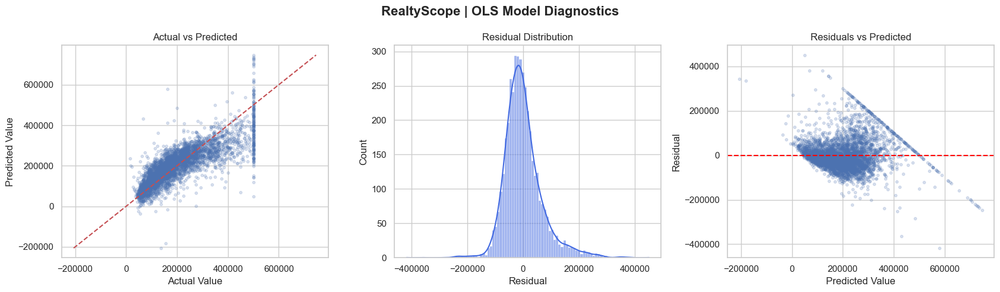

In [33]:

models = {"OLS": ols_model, **tuned_models}
results, predictions = [], {}

for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]

display(results_df.round(3))
print("Lowest Test RMSE:", best_name)


pred = predictions[best_name]
residuals = np.asarray(y_test) - pred

fig, ax = plt.subplots(1, 3, figsize=(17, 5))

ax[0].scatter(y_test, pred, alpha=0.2, s=10)
limits = [min(y_test.min(), pred.min()),
          max(y_test.max(), pred.max())]
ax[0].plot(limits, limits, "r--")
ax[0].set(xlabel="Actual Value", ylabel="Predicted Value",
          title="Actual vs Predicted")

sns.histplot(residuals, kde=True, ax=ax[1], color="royalblue")
ax[1].set(title="Residual Distribution", xlabel="Residual")

ax[2].scatter(pred, residuals, alpha=0.2, s=10)
ax[2].axhline(0, color="red", linestyle="--")
ax[2].set(xlabel="Predicted Value", ylabel="Residual",
          title="Residuals vs Predicted")

plt.suptitle(f"RealtyScope | {best_name} Model Diagnostics",
             fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


In [34]:

import ipywidgets as widgets
from IPython.display import display

location = widgets.Dropdown(
    options=["All"] + sorted(df["ocean_proximity"].unique().tolist()),
    description="Location:"
)
income = widgets.FloatSlider(
    value=0, min=0, max=15, step=0.5,
    description="Min Income:", continuous_update=False
)
output = widgets.Output()

def update_dashboard(change=None):
    data = df[
        (df["median_income"] >= income.value) &
        ((df["ocean_proximity"] == location.value)
         if location.value != "All" else True)
    ]
    with output:
        output.clear_output(wait=True)
        if data.empty:
            print("No housing districts match these filters.")
            return
        print(f"Districts: {len(data):,} | "
              f"Avg Value: ${data['median_house_value'].mean():,.0f} | "
              f"Median Value: ${data['median_house_value'].median():,.0f}")
        fig = px.scatter(
            data, x="median_income", y="median_house_value",
            color="ocean_proximity", opacity=0.5,
            title="RealtyScope | Income vs Housing Value"
        )
        fig.show()
        px.histogram(
            data, x="median_house_value", nbins=40,
            title="RealtyScope | Housing Value Distribution"
        ).show()

location.observe(update_dashboard, names="value")
income.observe(update_dashboard, names="value")

display(widgets.VBox([location, income, output]))
update_dashboard()


,Rank,Model,RMSE,MAE,R2
0,1,OLS,69048.192,49376.489,0.636
2,2,Lasso,69049.248,49377.343,0.636
1,3,Ridge,69056.220,49382.628,0.636


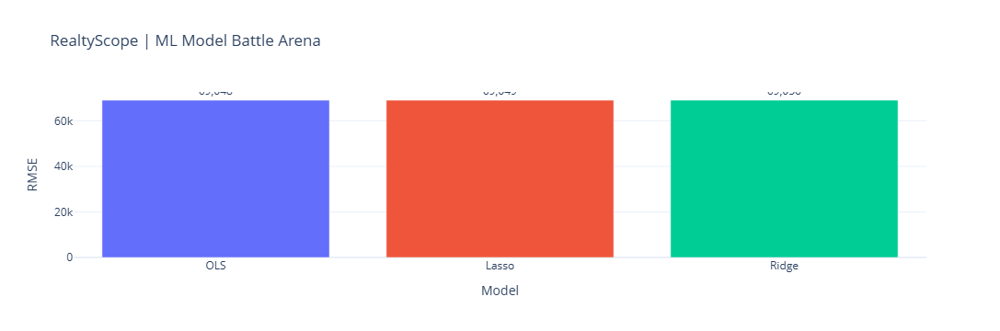

Lowest Test RMSE: OLS


,Feature,Coefficient,Importance
14,cat__ocean_proximity_ISLAND,112691.782,112691.782
7,num__median_income,68639.766,68639.766
1,num__latitude,-57595.466,57595.466
0,num__longitude,-57157.153,57157.153
13,cat__ocean_proximity_INLAND,-53876.660,53876.660
5,num__population,-46249.724,46249.724
6,num__households,40612.349,40612.349
15,cat__ocean_proximity_NEAR BAY,-24153.193,24153.193
12,cat__ocean_proximity_<1H OCEAN,-18553.723,18553.723
9,num__bedrooms_per_room,17576.151,17576.151


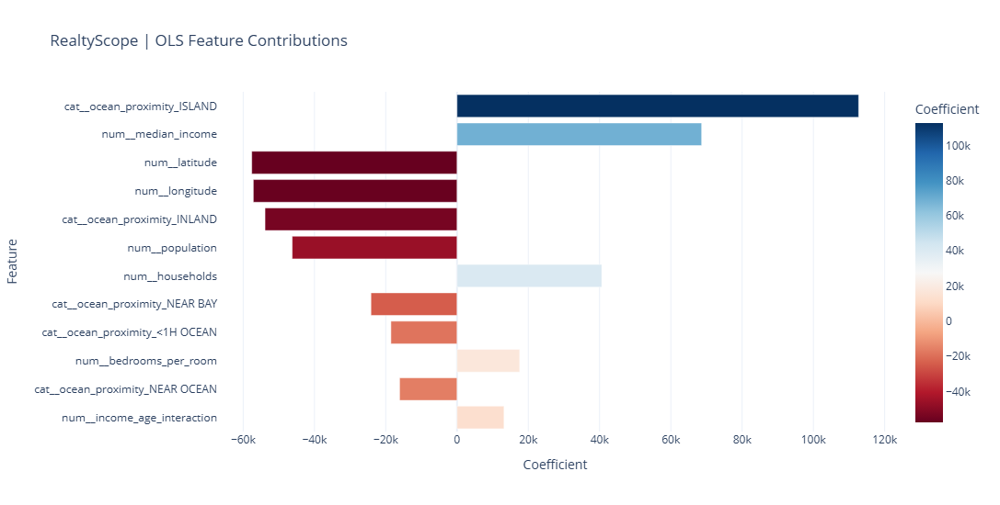

In [35]:

battle = results_df.sort_values("RMSE").copy()
battle["Rank"] = range(1, len(battle) + 1)

display(battle[["Rank", "Model", "RMSE", "MAE", "R2"]].round(3))

fig = px.bar(
    battle, x="Model", y="RMSE", color="Model",
    text="RMSE", title="RealtyScope | ML Model Battle Arena",
    hover_data=["MAE", "R2"]
)
fig.update_traces(texttemplate="%{text:,.0f}", textposition="outside")
fig.update_layout(template="plotly_white", showlegend=False)
fig.show()

print("Lowest Test RMSE:", battle.iloc[0]["Model"])

pipeline = best_model
features = pipeline.named_steps["preprocessing"].get_feature_names_out()
coefs = pipeline.named_steps["model"].coef_

importance = pd.DataFrame({
    "Feature": features,
    "Coefficient": coefs,
    "Importance": abs(coefs)
}).sort_values("Importance", ascending=False)

display(importance.head(10).round(3))

fig = px.bar(
    importance.head(12).sort_values("Importance"),
    x="Coefficient", y="Feature", orientation="h",
    color="Coefficient", color_continuous_scale="RdBu",
    title=f"RealtyScope | {best_name} Feature Contributions"
)
fig.update_layout(template="plotly_white", height=550)
fig.show()



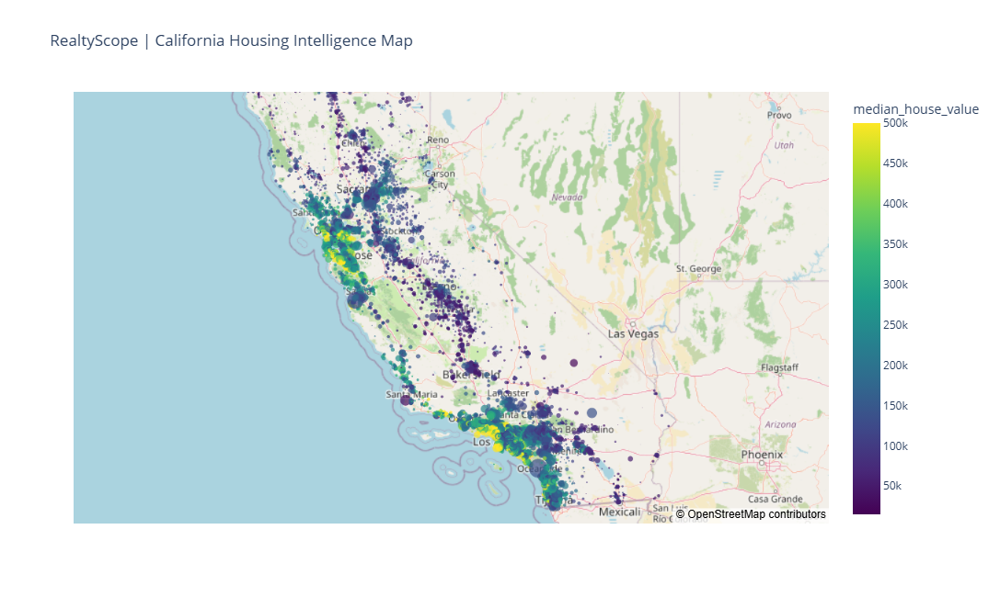

In [36]:

fig = px.scatter_map(
    df, lat="latitude", lon="longitude",
    color="median_house_value",
    size="population", size_max=15,
    hover_data=["median_income", "ocean_proximity"],
    color_continuous_scale="Viridis",
    zoom=5, center={"lat": 36.5, "lon": -119.5},
    title="RealtyScope | California Housing Intelligence Map",
    height=650
)

fig.update_layout(map_style="open-street-map")
fig.show()

from IPython.display import display

inputs = {
    "median_income": widgets.FloatSlider(value=4, min=0.5, max=15, step=0.5, description="Income"),
    "housing_median_age": widgets.IntSlider(value=25, min=1, max=52, description="Age"),
    "total_rooms": widgets.IntSlider(value=2500, min=100, max=10000, step=100, description="Rooms"),
    "total_bedrooms": widgets.IntSlider(value=500, min=20, max=3000, step=20, description="Bedrooms"),
    "population": widgets.IntSlider(value=1500, min=100, max=10000, step=100, description="Population"),
    "households": widgets.IntSlider(value=500, min=50, max=3000, step=50, description="Households"),
    "latitude": widgets.FloatSlider(value=34.05, min=32.5, max=42, step=0.05, description="Latitude"),
    "longitude": widgets.FloatSlider(value=-118.25, min=-124.5, max=-114, step=0.05, description="Longitude"),
    "ocean_proximity": widgets.Dropdown(options=sorted(df["ocean_proximity"].unique()), description="Ocean")
}

button = widgets.Button(description="Predict House Value", button_style="success")
result = widgets.Output()

def predict_house(change):
    with result:
        result.clear_output()
        sample = pd.DataFrame([{k: v.value for k, v in inputs.items()}])
        sample = add_housing_features(sample)
        prediction = best_model.predict(sample)[0]
        print(f"Predicted Median House Value: ${prediction:,.2f}")

button.on_click(predict_house)

display(widgets.VBox(list(inputs.values()) + [button, result]))


In [37]:

# RealtyScope - Final Model Selection

from sklearn.model_selection import cross_val_score

cv_scores = {
    name: -cross_val_score(
        model, X_train, y_train, cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    ).mean()
    for name, model in models.items()
}

final_name = min(cv_scores, key=cv_scores.get)
final_model = models[final_name]

print("Selected Model:", final_name)
print(f"CV RMSE: ${cv_scores[final_name]:,.2f}")

final_pred = final_model.predict(X_test)
print(f"Test RMSE: ${np.sqrt(mean_squared_error(y_test, final_pred)):,.2f}")
print(f"Test MAE: ${mean_absolute_error(y_test, final_pred):,.2f}")
print(f"Test R²: {r2_score(y_test, final_pred):.4f}")


Selected Model: Ridge
CV RMSE: $67,720.72
Test RMSE: $69,056.22
Test MAE: $49,382.63
Test R²: 0.6361
